# Đặc trưng và giới hạn lịch sử

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


Lag 28/35/42/56 và trung bình trượt 7/28 ngày dùng doanh số tối đa đến t−28, đồng thời giới hạn ở forecast origin. SNAP từ bang và ngày trong tháng theo quy tắc khóa từ lịch đến d_1885. One-hot áp dụng cho năm định danh, giữ vocabulary và thứ tự cột. [Mã đặc trưng](../src/wrmsse_stage2_data.py) · [Hậu kiểm SNAP](../docs/STAGE3_SNAP_REVIEW.md).

In [2]:
from src.wrmsse_stage2_data import CATS, BASE, numeric_block
features = read(STAGE4 / "final_feature_metadata.json")
assert list(features["logical_features"]) == CATS + BASE + ["snap_state"]
display(pd.Series(features["logical_features"], name="thứ_tự_đặc_trưng"))
display({key: features[key] for key in ("logical_count", "encoded_count", "format", "history_cutoff_formula", "snap_rule")})

0             item_id
1             dept_id
2              cat_id
3            store_id
4            state_id
5                wday
6               month
7                year
8              lag_28
9              lag_35
10             lag_42
11             lag_56
12     rolling_mean_7
13    rolling_mean_28
14         snap_state
Name: thứ_tự_đặc_trưng, dtype: str

{'logical_count': 15,
 'encoded_count': 3082,
 'format': 'CSR float32',
 'history_cutoff_formula': 'min(target_day - 28, d_1913)',
 'snap_rule': {'CA': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
  'TX': [1, 3, 5, 6, 7, 9, 11, 12, 13, 15],
  'WI': [2, 3, 5, 6, 8, 9, 11, 12, 14, 15]}}

FE-09 hợp nhất RF-v4, giá quá khứ, SNAP và Behavior. FE-10 thêm Events. Hậu kiểm xác nhận Events trên cửa sổ Validation cho FE-05 và FE-10. FE-04 dùng RF-v1 + SNAP và có WRMSSE Validation thấp nhất trong các cấu hình đủ điều kiện.

,experiment,feature_set,logical,encoded,validation_wrmsse
29,FE-04,rf_v1 + snap,15,3082,0.623931
34,FE-09,rf_v4 + prices + snap + behavior,29,3096,0.632138
35,FE-10,rf_v4 + prices + snap + behavior + events,33,3118,0.636074


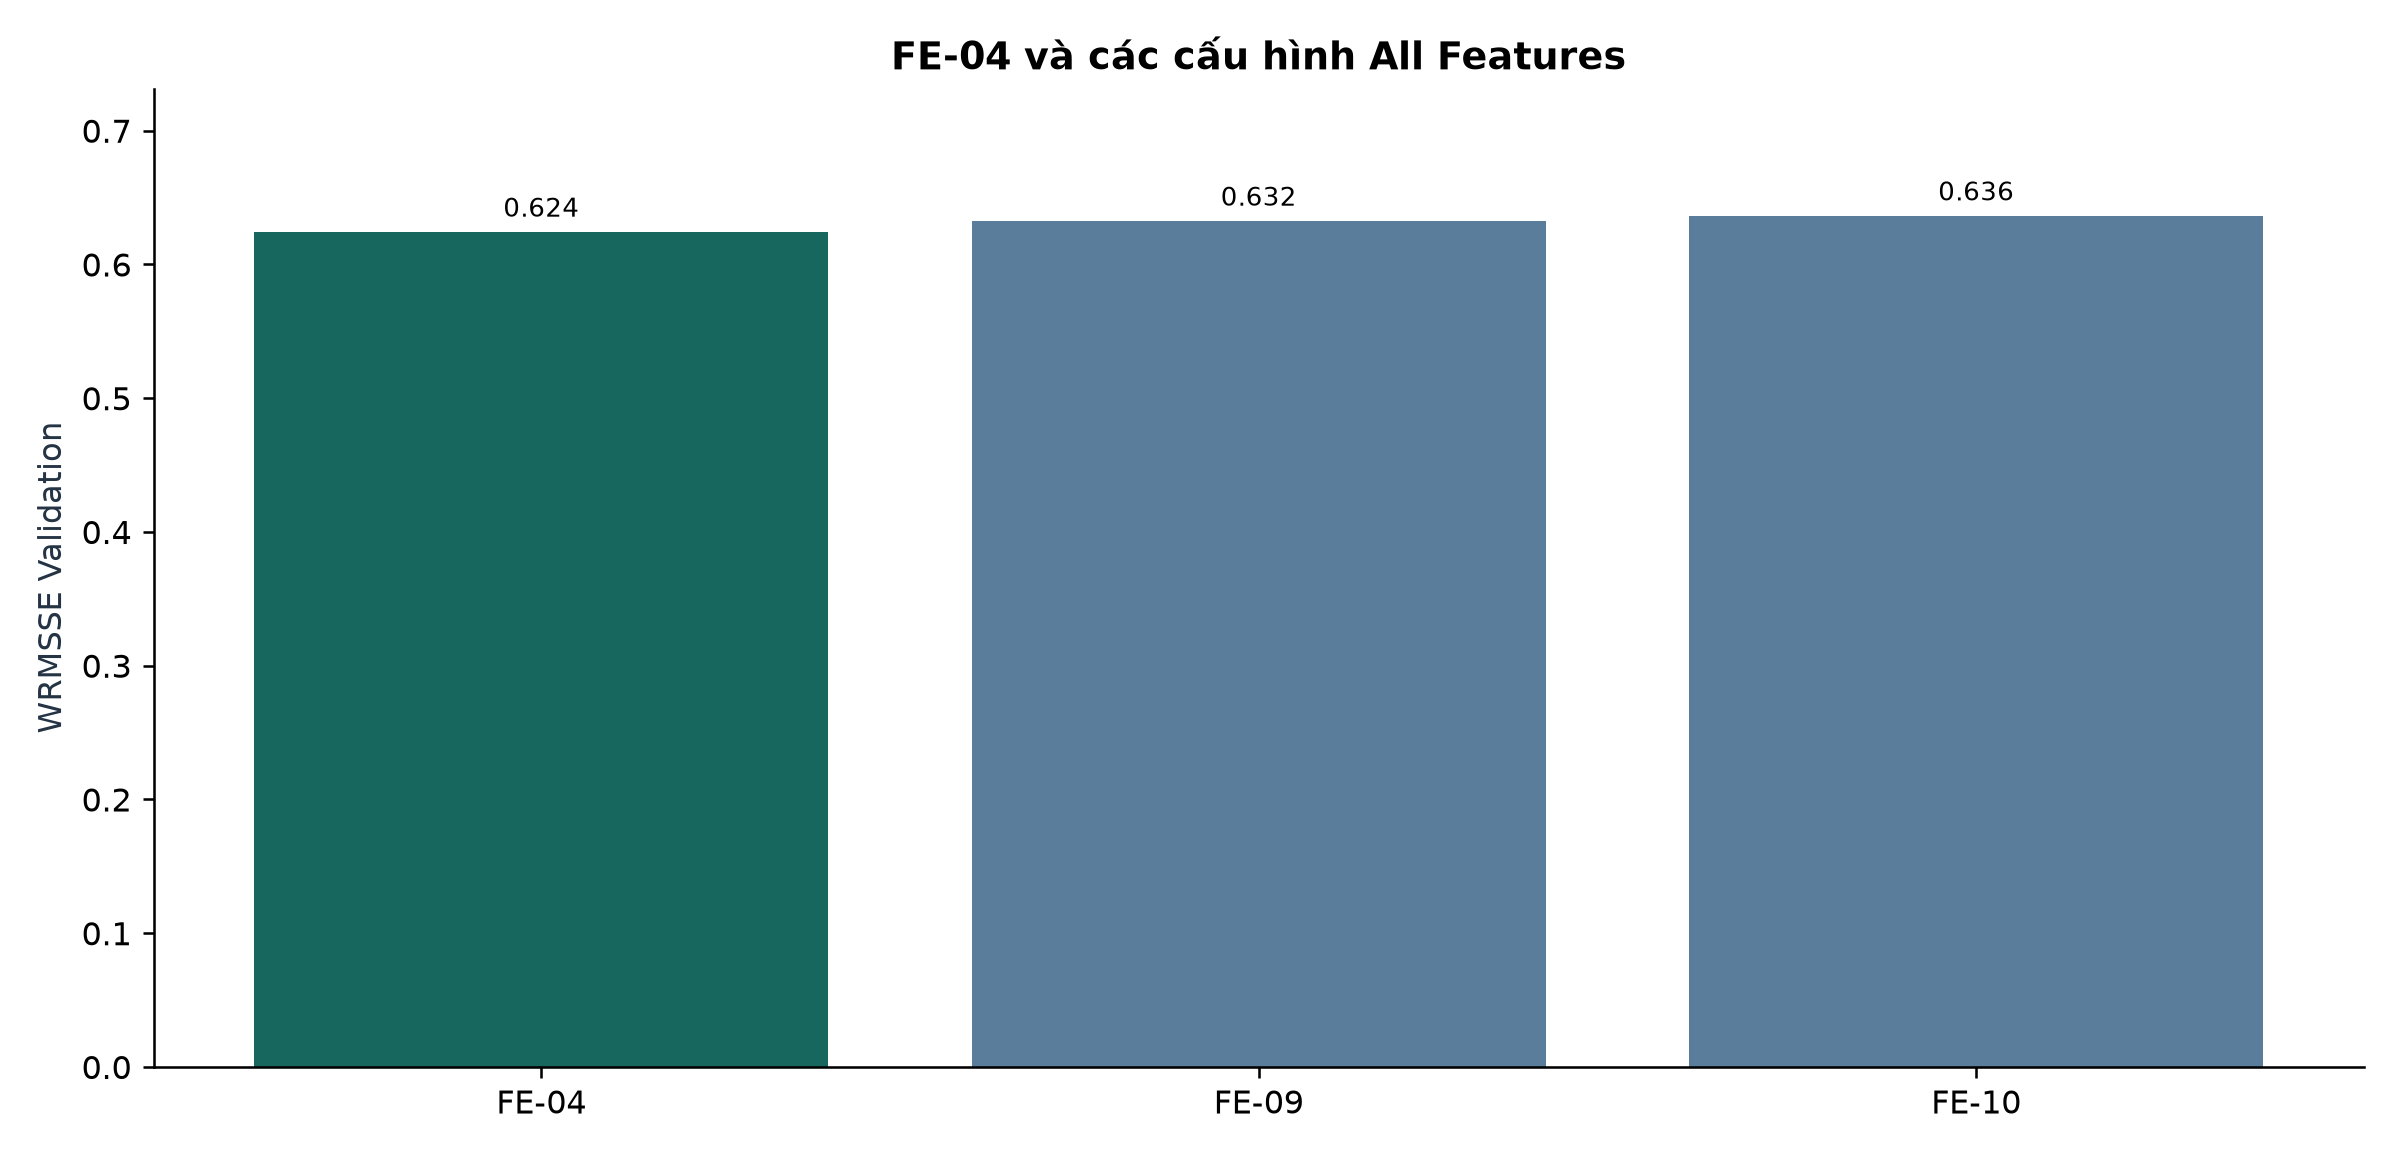

In [3]:
experiments = table("experiment_results")
display(experiments[experiments.experiment.isin(["FE-04", "FE-09", "FE-10"])][["experiment", "feature_set", "logical", "encoded", "validation_wrmsse"]])
figure(7)